In [ ]:
# Path setup: notebooks live in notebooks/, but every path below is relative to the repo root
import os
from pathlib import Path

_here = Path.cwd()
for _cand in (_here, *_here.parents):
    if (_cand / "README.md").exists() and (_cand / "notebooks").is_dir():
        os.chdir(_cand)
        break
print("Working directory:", Path.cwd())

In [ ]:
# ==============================
# STEP 2.1: IMPORT VISUALIZATION LIBRARIES
# ==============================
import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import ConnectionPatch
import random
from ultralytics import YOLO
import os

print("🎨 STEP 2: Keypoint Visualization and Data Analysis")
print("=" * 60)

🎨 STEP 2: Keypoint Visualization and Data Analysis


In [ ]:
# ==============================
# STEP 2.2: CONFIGURATION FOR VISUALIZATION
# ==============================
VIS_CONFIG = {
    # Model paths (from Step 1 training)
    'side_model_path': r"C:\Users\veerp\Downloads\runs\side_view\yolov8_cow_side_v1\weights\best.pt",
    'back_model_path': r"C:\Users\veerp\Downloads\runs\back_view\yolov8_cow_back_v1\weights\best.pt",
    
    # Data paths
    'side_images': r"C:\Users\veerp\Downloads\left_side_view",
    'back_images': r"C:\Users\veerp\Downloads\back_view",
    
    # Visualization settings
    'sample_size': 6,  # Number of sample images to visualize
    'keypoint_radius': 8,
    'skeleton_thickness': 4,
    'text_thickness': 2,
    
    # Colors (BGR format)
    'colors': {
        'keypoints': [(0, 0, 255), (0, 255, 0), (255, 0, 0), (255, 255, 0), 
                     (255, 0, 255), (0, 255, 255), (128, 0, 128), (128, 128, 0),
                     (0, 128, 128), (128, 0, 0)],
        'skeleton': (0, 255, 0),  # Green
        'text': (255, 255, 255)   # White
    },
    
    # Measurement connections with labels
    'side_connections': {
        (0, 9): 'Head Length',
        (2, 4): 'Oblique Body Length', 
        (5, 6): 'Girth Length',
        (1, 7): 'Chest Depth',
        (1, 8): 'Wither Height',
        (3, 4): 'Rump Angle'
    },
    
    'back_connections': {
        (0, 1): 'Rump Width',
        (2, 3): 'Hip Width', 
        (4, 5): 'Tail Length',
        (2, 6): 'Left Hip Height',
        (3, 7): 'Right Hip Height',
        (0, 2): 'Thurl Width (L)',
        (1, 3): 'Thurl Width (R)'
    }
}

print("✅ Visualization configuration loaded")

✅ Visualization configuration loaded


In [ ]:
# ==============================
# STEP 2.3: LOAD TRAINED MODELS
# ==============================
def load_trained_models():
    """Load the trained YOLO pose models"""
    print("\n🔧 Loading trained models...")
    
    try:
        side_model = YOLO(VIS_CONFIG['side_model_path'])
        print(f"✅ Side view model loaded: {VIS_CONFIG['side_model_path']}")
    except Exception as e:
        print(f"❌ Error loading side model: {e}")
        side_model = None
    
    try:
        back_model = YOLO(VIS_CONFIG['back_model_path'])
        print(f"✅ Back view model loaded: {VIS_CONFIG['back_model_path']}")
    except Exception as e:
        print(f"❌ Error loading back model: {e}")
        back_model = None
    
    return side_model, back_model

side_model, back_model = load_trained_models()


🔧 Loading trained models...
✅ Side view model loaded: C:\Users\veerp\Downloads\runs\side_view\yolov8_cow_side_v1\weights\best.pt
✅ Back view model loaded: C:\Users\veerp\Downloads\runs\back_view\yolov8_cow_back_v1\weights\best.pt


In [ ]:
# ==============================
# STEP 2.4: KEYPOINT VISUALIZATION FUNCTIONS
# ==============================
def draw_keypoints_with_skeleton(image, keypoints, connections, view_type):
    """
    Draw keypoints and skeleton connections on image with measurement labels
    """
    img_vis = image.copy()
    h, w = img_vis.shape[:2]
    
    # Thicker visualization config overrides
    skeleton_thickness = 4   # was thinner, now thicker lines
    keypoint_radius = 8      # bigger keypoints
    text_thickness = 3       # bolder text
    font_scale = 0.9         # slightly larger text
    
    # Draw skeleton connections
    for (i, j), label in connections.items():
        if i < len(keypoints) and j < len(keypoints):
            pt1 = (int(keypoints[i][0]), int(keypoints[i][1]))
            pt2 = (int(keypoints[j][0]), int(keypoints[j][1]))
            
            # Draw thicker line
            cv2.line(img_vis, pt1, pt2, VIS_CONFIG['colors']['skeleton'], 
                     skeleton_thickness)
            
            # Calculate midpoint for label
            mid_x = (pt1[0] + pt2[0]) // 2
            mid_y = (pt1[1] + pt2[1]) // 2
            
            # Draw bolder text label
            cv2.putText(img_vis, label, (mid_x + 10, mid_y), 
                        cv2.FONT_HERSHEY_SIMPLEX, font_scale, 
                        VIS_CONFIG['colors']['text'], text_thickness)
    
    # Draw keypoints with numbers
    for idx, (x, y) in enumerate(keypoints):
        center = (int(x), int(y))
        color = VIS_CONFIG['colors']['keypoints'][idx % len(VIS_CONFIG['colors']['keypoints'])]
        
        # Draw bigger circle
        cv2.circle(img_vis, center, keypoint_radius, color, -1)
        
        # Draw larger keypoint number
        cv2.putText(img_vis, str(idx), (center[0] + 14, center[1]), 
                    cv2.FONT_HERSHEY_SIMPLEX, font_scale, (255, 255, 255), 3)
        cv2.putText(img_vis, str(idx), (center[0] + 14, center[1]), 
                    cv2.FONT_HERSHEY_SIMPLEX, font_scale, (0, 0, 0), 1)
    
    return img_vis


def extract_keypoints_from_yolo(results):
    """Extract keypoints from YOLO results"""
    if len(results) == 0 or len(results[0].keypoints.xy) == 0:
        return None
    
    # Get keypoints from first detected object
    keypoints = results[0].keypoints.xy[0].cpu().numpy()
    return keypoints


In [ ]:
# ==============================
# STEP 2.5 (M):  IMAGE SELECTION
# ==============================
def get_sample_images(view_type, selected_files=None):
    """Get specific images for visualization instead of random samples"""
    if view_type == 'side':
        image_dir = VIS_CONFIG['side_images']
    else:
        image_dir = VIS_CONFIG['back_images']
    
    if selected_files:
        # Join the directory path with filenames provided
        sample_files = [os.path.join(image_dir, f) for f in selected_files]
    else:
        # fallback to random selection
        image_files = [f for f in os.listdir(image_dir) 
                       if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
        if len(image_files) > VIS_CONFIG['sample_size']:
            sample_files = random.sample(image_files, VIS_CONFIG['sample_size'])
        else:
            sample_files = image_files
    
    print(f"📸 Selected {len(sample_files)} {view_type} view images for visualization")
    return sample_files

# Example: choose your own filenames
side_sample_images = get_sample_images('side', selected_files=[
    "22.jpg", "71.jpg", "77.jpg", "78.jpg", "79.jpg", "80.jpg"
])

back_sample_images = get_sample_images('back', selected_files=[
    "71.png", "8.png", "10.png", "25.png", "34.png", "45.png"
])


📸 Selected 6 side view images for visualization
📸 Selected 6 back view images for visualization



🔄 Processing Side View Samples...

image 1/1 C:\Users\veerp\Downloads\left_side_view\22.jpg: 384x640 1 animal, 79.0ms
Speed: 3.4ms preprocess, 79.0ms inference, 1.9ms postprocess per image at shape (1, 3, 384, 640)
  Image 1: Detected 10 keypoints

image 1/1 C:\Users\veerp\Downloads\left_side_view\71.jpg: 480x640 1 animal, 56.7ms
Speed: 2.7ms preprocess, 56.7ms inference, 1.1ms postprocess per image at shape (1, 3, 480, 640)
  Image 2: Detected 10 keypoints

image 1/1 C:\Users\veerp\Downloads\left_side_view\77.jpg: 384x640 1 animal, 56.6ms
Speed: 3.0ms preprocess, 56.6ms inference, 1.3ms postprocess per image at shape (1, 3, 384, 640)
  Image 3: Detected 10 keypoints

image 1/1 C:\Users\veerp\Downloads\left_side_view\78.jpg: 640x480 2 animals, 66.6ms
Speed: 3.3ms preprocess, 66.6ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 480)
  Image 4: Detected 10 keypoints

image 1/1 C:\Users\veerp\Downloads\left_side_view\79.jpg: 384x640 2 animals, 75.4ms
Speed: 2.5ms preprocess

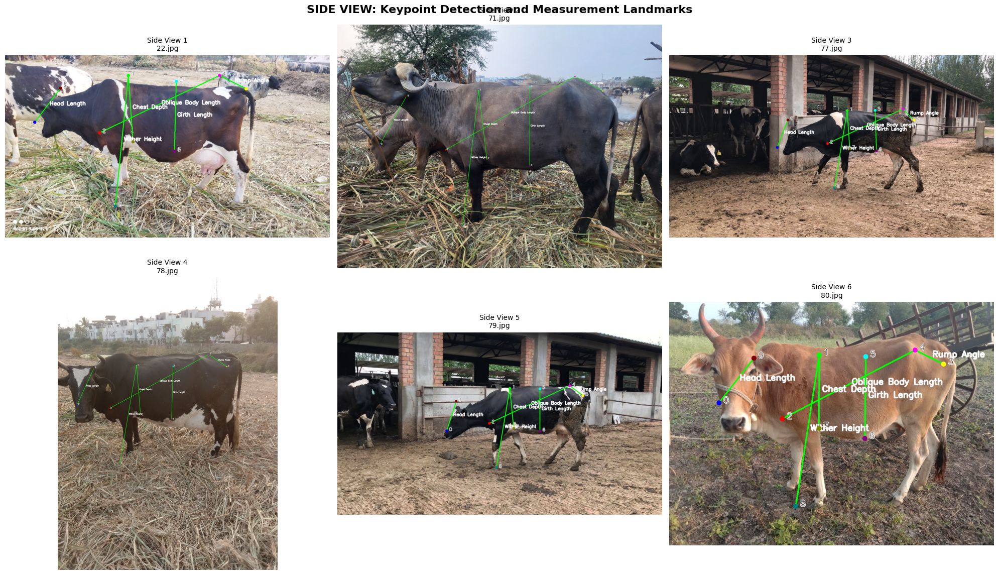

✅ Side view visualization completed and saved


In [ ]:
# ==============================
# STEP 2.6: VISUALIZE SIDE VIEW KEYPOINTS
# ==============================
def visualize_side_view_samples():
    """Visualize side view keypoints and measurements"""
    print("\n🔄 Processing Side View Samples...")
    
    if not side_model:
        print("❌ Side model not available, skipping visualization")
        return
    
    # Create figure for side view
    fig, axes = plt.subplots(2, 3, figsize=(20, 12))
    fig.suptitle('SIDE VIEW: Keypoint Detection and Measurement Landmarks', 
                fontsize=16, fontweight='bold', y=0.95)
    
    axes = axes.flatten()
    
    for idx, img_path in enumerate(side_sample_images[:6]):
        try:
            # Run inference
            results = side_model.predict(img_path, imgsz=640, conf=0.5)
            
            # Load original image
            img_bgr = cv2.imread(img_path)
            img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
            
            # Extract keypoints
            keypoints = extract_keypoints_from_yolo(results)
            
            if keypoints is not None:
                # Draw visualization
                vis_img = draw_keypoints_with_skeleton(
                    img_rgb, keypoints, VIS_CONFIG['side_connections'], 'side'
                )
                
                # Plot
                axes[idx].imshow(vis_img)
                axes[idx].set_title(f'Side View {idx+1}\n{os.path.basename(img_path)}', 
                                  fontsize=10)
                axes[idx].axis('off')
                
                # Print keypoint coordinates for debugging
                print(f"  Image {idx+1}: Detected {len(keypoints)} keypoints")
                
            else:
                # Show original image if no keypoints detected
                axes[idx].imshow(img_rgb)
                axes[idx].set_title(f'No Keypoints Detected\n{os.path.basename(img_path)}', 
                                  fontsize=10, color='red')
                axes[idx].axis('off')
                
        except Exception as e:
            print(f"❌ Error processing {img_path}: {e}")
            axes[idx].text(0.5, 0.5, f'Error\n{os.path.basename(img_path)}', 
                         ha='center', va='center', transform=axes[idx].transAxes,
                         fontsize=12, color='red')
            axes[idx].axis('off')
    
    plt.tight_layout()
    plt.savefig('side_view_keypoints_visualization.jpg', dpi=150, bbox_inches='tight')
    plt.show()
    
    print("✅ Side view visualization completed and saved")

# Run side view visualization
visualize_side_view_samples()


🔄 Processing Back View Samples...

image 1/1 C:\Users\veerp\Downloads\back_view\71.png: 640x480 1 animal, 76.6ms
Speed: 5.0ms preprocess, 76.6ms inference, 1.0ms postprocess per image at shape (1, 3, 640, 480)
  Image 1: Detected 8 keypoints

image 1/1 C:\Users\veerp\Downloads\back_view\8.png: 640x480 1 animal, 59.5ms
Speed: 2.9ms preprocess, 59.5ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 480)
  Image 2: Detected 8 keypoints

image 1/1 C:\Users\veerp\Downloads\back_view\10.png: 640x480 1 animal, 66.9ms
Speed: 2.6ms preprocess, 66.9ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 480)
  Image 3: Detected 8 keypoints

image 1/1 C:\Users\veerp\Downloads\back_view\25.png: 640x480 1 animal, 55.2ms
Speed: 3.5ms preprocess, 55.2ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 480)
  Image 4: Detected 8 keypoints

image 1/1 C:\Users\veerp\Downloads\back_view\34.png: 640x480 1 animal, 51.2ms
Speed: 2.6ms preprocess, 51.2ms inference, 0.9ms postpr

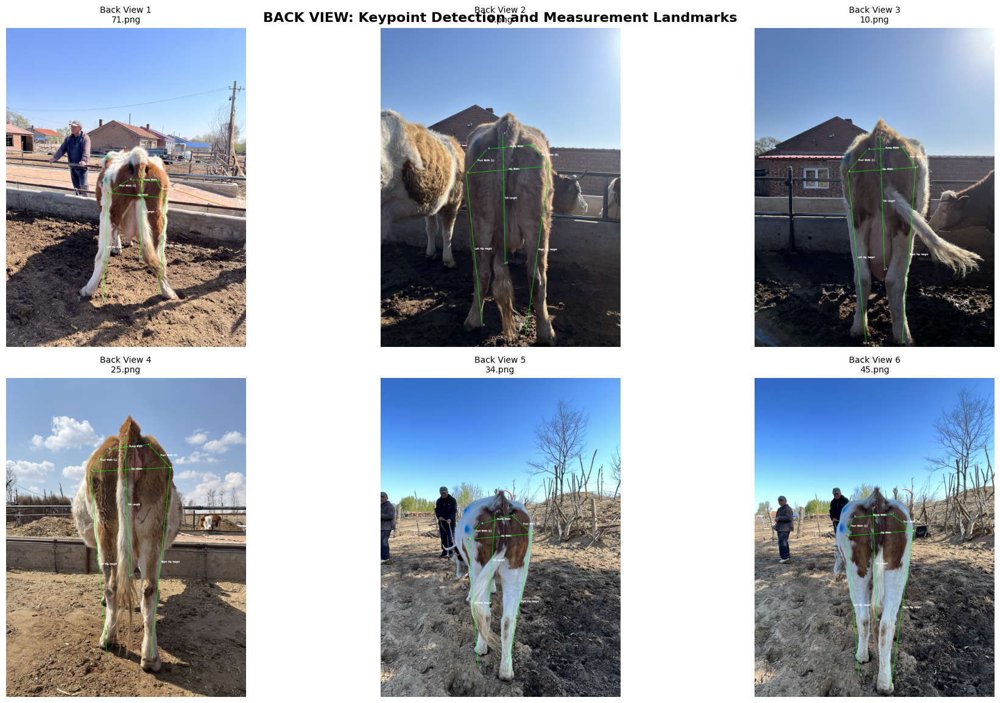

✅ Back view visualization completed and saved


In [ ]:
# ==============================
# STEP 2.7: VISUALIZE BACK VIEW KEYPOINTS
# ==============================
def visualize_back_view_samples():
    """Visualize back view keypoints and measurements"""
    print("\n🔄 Processing Back View Samples...")
    
    if not back_model:
        print("❌ Back model not available, skipping visualization")
        return
    
    # Create figure for back view
    fig, axes = plt.subplots(2, 3, figsize=(20, 12))
    fig.suptitle('BACK VIEW: Keypoint Detection and Measurement Landmarks', 
                fontsize=16, fontweight='bold', y=0.95)
    
    axes = axes.flatten()
    
    for idx, img_path in enumerate(back_sample_images[:6]):
        try:
            # Run inference
            results = back_model.predict(img_path, imgsz=640, conf=0.5)
            
            # Load original image
            img_bgr = cv2.imread(img_path)
            img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
            
            # Extract keypoints
            keypoints = extract_keypoints_from_yolo(results)
            
            if keypoints is not None:
                # Draw visualization
                vis_img = draw_keypoints_with_skeleton(
                    img_rgb, keypoints, VIS_CONFIG['back_connections'], 'back'
                )
                
                # Plot
                axes[idx].imshow(vis_img)
                axes[idx].set_title(f'Back View {idx+1}\n{os.path.basename(img_path)}', 
                                  fontsize=10)
                axes[idx].axis('off')
                
                # Print keypoint coordinates for debugging
                print(f"  Image {idx+1}: Detected {len(keypoints)} keypoints")
                
            else:
                # Show original image if no keypoints detected
                axes[idx].imshow(img_rgb)
                axes[idx].set_title(f'No Keypoints Detected\n{os.path.basename(img_path)}', 
                                  fontsize=10, color='red')
                axes[idx].axis('off')
                
        except Exception as e:
            print(f"❌ Error processing {img_path}: {e}")
            axes[idx].text(0.5, 0.5, f'Error\n{os.path.basename(img_path)}', 
                         ha='center', va='center', transform=axes[idx].transAxes,
                         fontsize=12, color='red')
            axes[idx].axis('off')
    
    plt.tight_layout()
    plt.savefig('back_view_keypoints_visualization.jpg', dpi=150, bbox_inches='tight')
    plt.show()
    
    print("✅ Back view visualization completed and saved")

# Run back view visualization
visualize_back_view_samples()

In [ ]:
# ==============================
# STEP 2.8: KEYPOINT STATISTICS ANALYSIS
# ==============================
def analyze_keypoint_statistics():
    """Analyze keypoint detection statistics"""
    print("\n📊 Analyzing Keypoint Detection Statistics...")
    
    stats = {'side': {}, 'back': {}}
    
    # Analyze side view
    if side_model:
        side_detections = 0
        side_keypoints_count = []
        
        for img_path in side_sample_images:
            results = side_model.predict(img_path, imgsz=640, conf=0.3)
            keypoints = extract_keypoints_from_yolo(results)
            
            if keypoints is not None:
                side_detections += 1
                side_keypoints_count.append(len(keypoints))
        
        stats['side'] = {
            'detection_rate': side_detections / len(side_sample_images),
            'avg_keypoints': np.mean(side_keypoints_count) if side_keypoints_count else 0,
            'total_samples': len(side_sample_images)
        }
    
    # Analyze back view
    if back_model:
        back_detections = 0
        back_keypoints_count = []
        
        for img_path in back_sample_images:
            results = back_model.predict(img_path, imgsz=640, conf=0.3)
            keypoints = extract_keypoints_from_yolo(results)
            
            if keypoints is not None:
                back_detections += 1
                back_keypoints_count.append(len(keypoints))
        
        stats['back'] = {
            'detection_rate': back_detections / len(back_sample_images),
            'avg_keypoints': np.mean(back_keypoints_count) if back_keypoints_count else 0,
            'total_samples': len(back_sample_images)
        }
    
    # Print statistics
    print("📈 KEYPOINT DETECTION STATISTICS:")
    print("-" * 50)
    for view_type, data in stats.items():
        if data:
            print(f"{view_type.upper()} VIEW:")
            print(f"  Detection Rate: {data['detection_rate']:.1%}")
            print(f"  Average Keypoints: {data['avg_keypoints']:.1f}")
            print(f"  Samples Analyzed: {data['total_samples']}")
            print()
    
    return stats

# Run statistics analysis
keypoint_stats = analyze_keypoint_statistics()


📊 Analyzing Keypoint Detection Statistics...

image 1/1 C:\Users\veerp\Downloads\left_side_view\22.jpg: 384x640 1 animal, 44.9ms
Speed: 1.5ms preprocess, 44.9ms inference, 1.3ms postprocess per image at shape (1, 3, 384, 640)

image 1/1 C:\Users\veerp\Downloads\left_side_view\71.jpg: 480x640 1 animal, 52.3ms
Speed: 2.4ms preprocess, 52.3ms inference, 1.2ms postprocess per image at shape (1, 3, 480, 640)

image 1/1 C:\Users\veerp\Downloads\left_side_view\77.jpg: 384x640 1 animal, 91.8ms
Speed: 1.7ms preprocess, 91.8ms inference, 3.5ms postprocess per image at shape (1, 3, 384, 640)

image 1/1 C:\Users\veerp\Downloads\left_side_view\78.jpg: 640x480 2 animals, 49.5ms
Speed: 3.4ms preprocess, 49.5ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 480)

image 1/1 C:\Users\veerp\Downloads\left_side_view\79.jpg: 384x640 2 animals, 41.6ms
Speed: 1.9ms preprocess, 41.6ms inference, 1.5ms postprocess per image at shape (1, 3, 384, 640)

image 1/1 C:\Users\veerp\Downloads\left_side_v

In [ ]:
# ==============================
# STEP 2.9: MEASUREMENT LANDMARK EXPLANATION
# ==============================
def display_measurement_explanations():
    """Display explanation of measurement landmarks"""
    print("\n📐 MEASUREMENT LANDMARK EXPLANATIONS")
    print("=" * 60)
    
    print("\n🔵 SIDE VIEW MEASUREMENTS (10 Keypoints):")
    print("-" * 40)
    for (i, j), measurement in VIS_CONFIG['side_connections'].items():
        print(f"  Keypoints {i}-{j}: {measurement}")
    
    print("\n🔴 BACK VIEW MEASUREMENTS (8 Keypoints):")
    print("-" * 40)
    for (i, j), measurement in VIS_CONFIG['back_connections'].items():
        print(f"  Keypoints {i}-{j}: {measurement}")
    
    print("\n🎯 KEYPOINT NUMBERING:")
    print("Side View: 0-9 (10 points) | Back View: 0-7 (8 points)")
    print("Each number represents a specific anatomical landmark")

# Display explanations
display_measurement_explanations()


📐 MEASUREMENT LANDMARK EXPLANATIONS

🔵 SIDE VIEW MEASUREMENTS (10 Keypoints):
----------------------------------------
  Keypoints 0-9: Head Length
  Keypoints 2-4: Oblique Body Length
  Keypoints 5-6: Girth Length
  Keypoints 1-7: Chest Depth
  Keypoints 1-8: Wither Height
  Keypoints 3-4: Rump Angle

🔴 BACK VIEW MEASUREMENTS (8 Keypoints):
----------------------------------------
  Keypoints 0-1: Rump Width
  Keypoints 2-3: Hip Width
  Keypoints 4-5: Tail Length
  Keypoints 2-6: Left Hip Height
  Keypoints 3-7: Right Hip Height
  Keypoints 0-2: Thurl Width (L)
  Keypoints 1-3: Thurl Width (R)

🎯 KEYPOINT NUMBERING:
Side View: 0-9 (10 points) | Back View: 0-7 (8 points)
Each number represents a specific anatomical landmark



🔄 Creating Comparative Visualization...

image 1/1 C:\Users\veerp\Downloads\left_side_view\22.jpg: 384x640 1 animal, 81.6ms
Speed: 2.5ms preprocess, 81.6ms inference, 1.4ms postprocess per image at shape (1, 3, 384, 640)

image 1/1 C:\Users\veerp\Downloads\back_view\71.png: 640x480 1 animal, 89.6ms
Speed: 4.2ms preprocess, 89.6ms inference, 2.8ms postprocess per image at shape (1, 3, 640, 480)


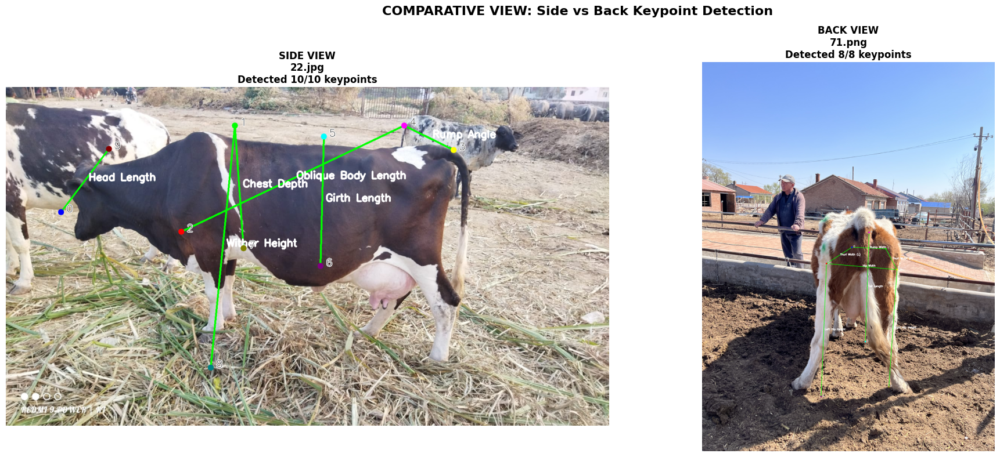

✅ Comparative visualization completed and saved


In [ ]:
# ==============================
# STEP 2.10: CREATE COMPARATIVE VISUALIZATION
# ==============================
def create_comparative_visualization():
    """Create side-by-side comparison of both views"""
    print("\n🔄 Creating Comparative Visualization...")
    
    if not side_model or not back_model:
        print("❌ Models not available for comparison")
        return
    
    # Get one sample from each view
    side_sample = side_sample_images[0] if side_sample_images else None
    back_sample = back_sample_images[0] if back_sample_images else None
    
    if not side_sample or not back_sample:
        print("❌ Not enough samples for comparison")
        return
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8))
    fig.suptitle('COMPARATIVE VIEW: Side vs Back Keypoint Detection', 
                fontsize=16, fontweight='bold')
    
    try:
        # Process side view
        results_side = side_model.predict(side_sample, imgsz=640)
        img_side = cv2.imread(side_sample)
        img_side = cv2.cvtColor(img_side, cv2.COLOR_BGR2RGB)
        keypoints_side = extract_keypoints_from_yolo(results_side)
        
        if keypoints_side is not None:
            vis_side = draw_keypoints_with_skeleton(
                img_side, keypoints_side, VIS_CONFIG['side_connections'], 'side'
            )
            ax1.imshow(vis_side)
            ax1.set_title(f'SIDE VIEW\n{os.path.basename(side_sample)}\n'
                         f'Detected {len(keypoints_side)}/10 keypoints', 
                         fontsize=12, fontweight='bold')
        else:
            ax1.imshow(img_side)
            ax1.set_title(f'SIDE VIEW\nNo Keypoints Detected', 
                         fontsize=12, color='red', fontweight='bold')
        
        ax1.axis('off')
        
        # Process back view
        results_back = back_model.predict(back_sample, imgsz=640)
        img_back = cv2.imread(back_sample)
        img_back = cv2.cvtColor(img_back, cv2.COLOR_BGR2RGB)
        keypoints_back = extract_keypoints_from_yolo(results_back)
        
        if keypoints_back is not None:
            vis_back = draw_keypoints_with_skeleton(
                img_back, keypoints_back, VIS_CONFIG['back_connections'], 'back'
            )
            ax2.imshow(vis_back)
            ax2.set_title(f'BACK VIEW\n{os.path.basename(back_sample)}\n'
                         f'Detected {len(keypoints_back)}/8 keypoints', 
                         fontsize=12, fontweight='bold')
        else:
            ax2.imshow(img_back)
            ax2.set_title(f'BACK VIEW\nNo Keypoints Detected', 
                         fontsize=12, color='red', fontweight='bold')
        
        ax2.axis('off')
        
        plt.tight_layout()
        plt.savefig('comparative_view_visualization.jpg', dpi=150, bbox_inches='tight')
        plt.show()
        
        print("✅ Comparative visualization completed and saved")
        
    except Exception as e:
        print(f"❌ Error in comparative visualization: {e}")

# Create comparative visualization
create_comparative_visualization()

# STEP 3: Measurement Extraction Pipeline

In [ ]:
# ==============================
# STEP 3.1: IMPORT MEASUREMENT LIBRARIES
# ==============================
import math
import pandas as pd
from scipy.spatial.distance import euclidean
from sklearn.linear_model import LinearRegression
import json
import os

print("📏 STEP 3: Measurement Extraction Pipeline")
print("=" * 60)

📏 STEP 3: Measurement Extraction Pipeline


In [ ]:
# ==============================
# STEP 3.2: MEASUREMENT CONFIGURATION
# ==============================
MEASUREMENT_CONFIG = {
    # Measurement definitions with keypoint pairs
    'side_measurements': {
        'head_length': {'points': [0, 9], 'type': 'distance'},
        'oblique_body_length': {'points': [2, 4], 'type': 'distance'},
        'girth_length': {'points': [5, 6], 'type': 'distance'},
        'chest_depth': {'points': [1, 7], 'type': 'distance'},
        'withers_height': {'points': [1, 8], 'type': 'distance'},
        'rump_angle': {'points': [3, 4], 'type': 'angle'}  # Requires 3 points for angle
    },
    
    'back_measurements': {
        'rump_width': {'points': [0, 1], 'type': 'distance'},
        'hip_width': {'points': [2, 3], 'type': 'distance'},
        'tail_length': {'points': [4, 5], 'type': 'distance'},
        'left_hip_height': {'points': [2, 6], 'type': 'distance'},
        'right_hip_height': {'points': [3, 7], 'type': 'distance'},
        'thurl_width': {'points': [0, 2, 1, 3], 'type': 'width'}  # Special case
    },
    
    # Biological plausibility ranges (cm) - can be updated based on actual data
    'plausibility_ranges': {
        'head_length': (35, 65),
        'oblique_body_length': (120, 180),
        'girth_length': (160, 240),
        'chest_depth': (60, 100),
        'withers_height': (110, 150),
        'rump_angle': (20, 45),  # degrees
        'rump_width': (40, 80),
        'hip_width': (45, 85),
        'tail_length': (30, 70),
        'left_hip_height': (110, 150),
        'right_hip_height': (110, 150),
        'thurl_width': (35, 75)
    }
}

print("✅ Measurement configuration loaded")

✅ Measurement configuration loaded


In [ ]:
# ==============================
# STEP 3.3: GEOMETRIC CALCULATION FUNCTIONS
# ==============================
def calculate_distance(point1, point2):
    """Calculate Euclidean distance between two points"""
    return euclidean(point1, point2)

def calculate_angle(point1, vertex, point2):
    """
    Calculate angle at vertex formed by three points
    Returns angle in degrees
    """
    # Create vectors from vertex
    vec1 = point1 - vertex
    vec2 = point2 - vertex
    
    # Calculate dot product and magnitudes
    dot_product = np.dot(vec1, vec2)
    mag1 = np.linalg.norm(vec1)
    mag2 = np.linalg.norm(vec2)
    
    # Avoid division by zero
    if mag1 == 0 or mag2 == 0:
        return 0.0
    
    # Calculate cosine of angle
    cos_angle = dot_product / (mag1 * mag2)
    
    # Clamp to avoid numerical issues
    cos_angle = np.clip(cos_angle, -1.0, 1.0)
    
    # Convert to degrees
    angle_rad = math.acos(cos_angle)
    angle_deg = math.degrees(angle_rad)
    
    return angle_deg

def calculate_thurl_width(points):
    """
    Calculate thurl width as the distance between two lines
    points: [left_rump, left_hip, right_rump, right_hip]
    """
    if len(points) < 4:
        return 0.0
    
    left_rump, left_hip, right_rump, right_hip = points[:4]
    
    # Calculate midpoints of left and right sides
    left_mid = (left_rump + left_hip) / 2
    right_mid = (right_rump + right_hip) / 2
    
    # Thurl width is distance between these midpoints
    return calculate_distance(left_mid, right_mid)

def extract_all_measurements(keypoints, view_type):
    """
    Extract all measurements for a given view type
    Returns dictionary of measurements in pixels
    """
    measurements = {}
    
    if view_type == 'side':
        measurement_defs = MEASUREMENT_CONFIG['side_measurements']
        required_points = 10
    else:  # back view
        measurement_defs = MEASUREMENT_CONFIG['back_measurements']
        required_points = 8
    
    # Check if we have enough keypoints
    if keypoints is None or len(keypoints) < required_points:
        print(f"⚠️ Insufficient keypoints for {view_type} view: {len(keypoints) if keypoints else 0}/{required_points}")
        return measurements
    
    try:
        for measurement_name, config in measurement_defs.items():
            points_needed = config['points']
            measurement_type = config['type']
            
            if measurement_type == 'distance':
                # Simple distance between two points
                if len(points_needed) == 2:
                    point1 = keypoints[points_needed[0]]
                    point2 = keypoints[points_needed[1]]
                    measurements[measurement_name] = calculate_distance(point1, point2)
                
            elif measurement_type == 'angle':
                # Angle calculation (rump angle needs 3 points)
                if len(points_needed) == 2:
                    # For rump angle, we need points 3, 4 and an additional reference
                    if measurement_name == 'rump_angle':
                        # Use points 3, 4 and create a horizontal reference from point 3
                        point1 = keypoints[3]  # Rump point 1
                        vertex = keypoints[4]   # Rump point 2 (vertex)
                        # Create horizontal reference point
                        point2 = np.array([vertex[0] + 100, vertex[1]])  # Horizontal line
                        measurements[measurement_name] = calculate_angle(point1, vertex, point2)
                
            elif measurement_type == 'width':
                # Thurl width calculation
                if len(points_needed) == 4:
                    points_list = [keypoints[i] for i in points_needed]
                    measurements[measurement_name] = calculate_thurl_width(points_list)
        
        print(f"✅ Extracted {len(measurements)} measurements from {view_type} view")
        
    except Exception as e:
        print(f"❌ Error extracting measurements: {e}")
    
    return measurements

In [ ]:
# ==============================
# STEP 3.4: LOAD EXCEL MEASUREMENTS FOR SCALING
# ==============================
import os
import pandas as pd
def load_excel_measurements():
    """Load ground truth measurements from Excel file"""
    print("\n📊 Loading Excel measurements for scaling...")
    
    try:
        # Try different possible file locations and names
        excel_paths = [
            r"C:\Users\veerp\Downloads\measurements-og.xlsx",
            r"C:\Users\veerp\Downloads\measurements.xlsx",
        ]
        
        excel_path = None
        for path in excel_paths:
            if os.path.exists(path):
                excel_path = path
                break
        
        if not excel_path:
            print("❌ Excel measurements file not found")
            return None
        
        df = pd.read_excel(excel_path)
        df['image_id'] = df['image_id'].astype(str)
        
        print(f"✅ Excel data loaded: {len(df)} records")
        print(f"📋 Columns: {list(df.columns)}")
        
        # Display sample of the data
        print("\n📄 Sample data from Excel:")
        print(df.head(3).to_string(index=False))
        
        return df
        
    except Exception as e:
        print(f"❌ Error loading Excel file: {e}")
        return None

# Load Excel measurements
excel_df = load_excel_measurements()


📊 Loading Excel measurements for scaling...
✅ Excel data loaded: 83 records
📋 Columns: ['image_id', 'Oblique_body_length_cm', 'Withers_height_cm', 'Heart_girth_cm', 'Hip_length_cm', 'Body_weight_kg']

📄 Sample data from Excel:
image_id  Oblique_body_length_cm  Withers_height_cm  Heart_girth_cm  Hip_length_cm  Body_weight_kg
       1                     161                124             190             47             545
       2                     152                120             183             43             507
       3                     151                124             179             41             450


In [ ]:
import os
import pandas as pd
from ultralytics import YOLO

# =========================================================
# 🛠️ MASTER REPAIR CELL (Run this once to fix variables)
# =========================================================

print("🔧 Restoring VETRA Configuration and Models...")

# 1. DEFINE MEASUREMENT_CONFIG (Fixes the crash at line 38)
MEASUREMENT_CONFIG = {
    'side_measurements': {
        'head_length': {'points': [0, 9], 'type': 'distance'},
        'oblique_body_length': {'points': [2, 4], 'type': 'distance'},
        'girth_length': {'points': [5, 6], 'type': 'distance'},
        'chest_depth': {'points': [1, 7], 'type': 'distance'},
        'withers_height': {'points': [1, 8], 'type': 'distance'},
        'rump_angle': {'points': [3, 4], 'type': 'angle'}
    },
    'back_measurements': {
        'rump_width': {'points': [0, 1], 'type': 'distance'},
        'hip_width': {'points': [2, 3], 'type': 'distance'},
        'tail_length': {'points': [4, 5], 'type': 'distance'},
        'left_hip_height': {'points': [2, 6], 'type': 'distance'},
        'right_hip_height': {'points': [3, 7], 'type': 'distance'},
        'thurl_width': {'points': [0, 2, 1, 3], 'type': 'width'}
    },
    'plausibility_ranges': {
        'head_length': (35, 65), 'oblique_body_length': (120, 180),
        'girth_length': (160, 240), 'chest_depth': (60, 100),
        'withers_height': (110, 150), 'rump_angle': (20, 45),
        'rump_width': (40, 80), 'hip_width': (45, 85),
        'tail_length': (30, 70), 'left_hip_height': (110, 150),
        'right_hip_height': (110, 150), 'thurl_width': (35, 75)
    }
}
print("✅ MEASUREMENT_CONFIG defined.")

# 2. LOAD MODELS FROM DISK (Fixes 'side_model'/'back_model' not defined)
# Using your specific absolute paths
back_path = r"C:\Users\veerp\Downloads\runs\back_view\yolov8_cow_back_v1\weights\best.pt"
side_path = r"C:\Users\veerp\Downloads\runs\side_view\yolov8_cow_side_v1\weights\best.pt"

# Load Side Model
if os.path.exists(side_path):
    side_model = YOLO(side_path)
    print(f"✅ Loaded side_model from: {side_path}")
else:
    print(f"❌ MISSING: Could not find side model at {side_path}")
    print("   👉 Check if the file path is correct or if training finished successfully.")

# Load Back Model
if os.path.exists(back_path):
    back_model = YOLO(back_path)
    print(f"✅ Loaded back_model from: {back_path}")
else:
    print(f"❌ MISSING: Could not find back model at {back_path}")
    print("   👉 Check if the file path is correct or if training finished successfully.")

print("\n🚀 Repair complete. You can now run the scaling factor calculation.")

🔧 Restoring VETRA Configuration and Models...
✅ MEASUREMENT_CONFIG defined.
✅ Loaded side_model from: C:\Users\veerp\Downloads\runs\side_view\yolov8_cow_side_v1\weights\best.pt
✅ Loaded back_model from: C:\Users\veerp\Downloads\runs\back_view\yolov8_cow_back_v1\weights\best.pt

🚀 Repair complete. You can now run the scaling factor calculation.


In [ ]:
# ==============================
# STEP 3.5: SCALING FACTOR CALCULATION
# ==============================
def calculate_scaling_factors():
    """
    Calculate pixel-to-cm scaling factors using Excel ground truth
    Returns dictionary of scaling factors for each measurement
    """
    print("\n🔧 Calculating scaling factors...")
    
    if excel_df is None:
        print("❌ No Excel data available for scaling calculation")
        return None
    
    scaling_factors = {}
    scaling_data = []
    
    # Process each image in Excel data
    for idx, row in excel_df.iterrows():
        image_id = str(row['image_id'])
        
        # Try to find corresponding keypoints for this image
        keypoints_side = load_keypoints_for_image(image_id, 'side')
        keypoints_back = load_keypoints_for_image(image_id, 'back')
        
        record = {'image_id': image_id}
        
        # Extract pixel measurements
        if keypoints_side is not None:
            pixel_measurements_side = extract_all_measurements(keypoints_side, 'side')
            record.update({f"{k}_pixels": v for k, v in pixel_measurements_side.items()})
        
        if keypoints_back is not None:
            pixel_measurements_back = extract_all_measurements(keypoints_back, 'back')
            record.update({f"{k}_pixels": v for k, v in pixel_measurements_back.items()})
        
        # Add ground truth measurements from Excel
        for measurement in MEASUREMENT_CONFIG['side_measurements'].keys():
            if measurement in row:
                record[f"{measurement}_cm"] = row[measurement]
        
        for measurement in MEASUREMENT_CONFIG['back_measurements'].keys():
            if measurement in row:
                record[f"{measurement}_cm"] = row[measurement]
        
        scaling_data.append(record)
    
    # Create scaling dataframe
    scaling_df = pd.DataFrame(scaling_data)
    valid_records = len([r for r in scaling_data if any('_pixels' in k for k in r.keys())])
    print(f"📈 Processed {valid_records} valid image-measurement pairs")
    
    # Calculate scaling factors for each measurement
    for measurement in list(MEASUREMENT_CONFIG['side_measurements'].keys()) + list(MEASUREMENT_CONFIG['back_measurements'].keys()):
        pixel_col = f"{measurement}_pixels"
        cm_col = f"{measurement}_cm"
        
        if pixel_col in scaling_df.columns and cm_col in scaling_df.columns:
            # Remove rows with missing data
            valid_data = scaling_df[[pixel_col, cm_col]].dropna()
            
            if len(valid_data) > 5:  # Need minimum samples
                X = valid_data[pixel_col].values.reshape(-1, 1)
                y = valid_data[cm_col].values
                
                # Use linear regression for robust scaling
                reg = LinearRegression()
                reg.fit(X, y)
                
                scaling_factors[measurement] = {
                    'slope': reg.coef_[0],
                    'intercept': reg.intercept_,
                    'r_squared': reg.score(X, y),
                    'samples': len(valid_data)
                }
                
                print(f"  {measurement:20}: {reg.coef_[0]:.4f} cm/pixel, R²={reg.score(X, y):.3f} (n={len(valid_data)})")
    
    # Save scaling data for analysis
    scaling_df.to_csv(r"C:\Users\veerp\Downloads\scaling_calibration_data.csv", index=False)
    print(f"💾 Scaling calibration data saved: scaling_calibration_data.csv")
    
    return scaling_factors

def load_keypoints_for_image(image_id, view_type):
    """Load keypoints for a specific image ID and view type"""
    try:
        if view_type == 'side':
            label_dir = 'data/labels_side'
            model = side_model
        else:
            label_dir = 'data/labels-back'
            model = back_model
        
        # Find label file
        label_path = os.path.join(label_dir, f"{image_id}.txt")
        if not os.path.exists(label_path):
            return None
        
        # Find corresponding image to get dimensions
        img_path = None
        for ext in ['.jpg', '.jpeg', '.png', '.JPG', '.JPEG', '.PNG']:
            if view_type == 'side':
                test_path = os.path.join(r"C:\Users\veerp\Downloads\left_side_view", f"{image_id}{ext}")
            else:
                test_path = os.path.join(r"C:\Users\veerp\Downloads\back_view", f"{image_id}{ext}")
            
            if os.path.exists(test_path):
                img_path = test_path
                break
        
        if not img_path:
            return None
        
        # Load image and keypoints using YOLO model
        results = model.predict(img_path, imgsz=640, conf=0.3)
        return extract_keypoints_from_yolo(results)
        
    except Exception as e:
        print(f"❌ Error loading keypoints for {image_id}_{view_type}: {e}")
        return None

# Calculate scaling factors
scaling_factors = calculate_scaling_factors()


🔧 Calculating scaling factors...
📈 Processed 0 valid image-measurement pairs
💾 Scaling calibration data saved: scaling_calibration_data.csv


In [ ]:
# ==============================
# STEP 3.6: MEASUREMENT CONVERSION TO CM
# ==============================
def convert_to_cm(pixel_measurements, scaling_factors):
    """Convert pixel measurements to centimeters using scaling factors"""
    cm_measurements = {}
    
    for measurement, pixel_value in pixel_measurements.items():
        if measurement in scaling_factors:
            factor = scaling_factors[measurement]
            cm_value = pixel_value * factor['slope'] + factor['intercept']
            cm_measurements[measurement] = cm_value
        else:
            # Use fallback scaling if no specific factor available
            cm_measurements[measurement] = pixel_value * 0.1  # Default fallback
    
    return cm_measurements

def validate_measurements(measurements_cm, view_type):
    """Validate measurements against biological plausibility ranges"""
    warnings = []
    
    if view_type == 'side':
        ranges = {k: MEASUREMENT_CONFIG['plausibility_ranges'][k] 
                 for k in MEASUREMENT_CONFIG['side_measurements'].keys()}
    else:
        ranges = {k: MEASUREMENT_CONFIG['plausibility_ranges'][k] 
                 for k in MEASUREMENT_CONFIG['back_measurements'].keys()}
    
    for measurement, value in measurements_cm.items():
        if measurement in ranges:
            min_val, max_val = ranges[measurement]
            if value < min_val or value > max_val:
                warnings.append(f"{measurement}: {value:.1f} cm (expected {min_val}-{max_val} cm)")
    
    return warnings

In [ ]:
# ==============================
# STEP 3.7: COMPLETE MEASUREMENT PIPELINE
# ==============================
def run_measurement_pipeline(image_path, view_type, scaling_factors):
    """
    Complete pipeline: Detect keypoints → Extract measurements → Convert to cm → Validate
    """
    print(f"\n🔍 Running measurement pipeline for {view_type} view: {os.path.basename(image_path)}")
    
    # Step 1: Load and detect keypoints
    if view_type == 'side':
        model = side_model
    else:
        model = back_model
    
    results = model.predict(image_path, imgsz=640, conf=0.5)
    keypoints = extract_keypoints_from_yolo(results)
    
    if keypoints is None:
        print("❌ No keypoints detected")
        return None, None, None
    
    print(f"✅ Detected {len(keypoints)} keypoints")
    
    # Step 2: Extract measurements in pixels
    pixel_measurements = extract_all_measurements(keypoints, view_type)
    
    if not pixel_measurements:
        print("❌ No measurements extracted")
        return None, None, None
    
    # Step 3: Convert to centimeters
    if scaling_factors:
        cm_measurements = convert_to_cm(pixel_measurements, scaling_factors)
    else:
        print("⚠️ Using fallback scaling (no calibration data)")
        cm_measurements = {k: v * 0.1 for k, v in pixel_measurements.items()}
    
    # Step 4: Validate measurements
    warnings = validate_measurements(cm_measurements, view_type)
    
    # Display results
    print(f"📏 EXTRACTED MEASUREMENTS ({view_type.upper()} VIEW):")
    print("-" * 50)
    for measurement, value in cm_measurements.items():
        status = "⚠️" if any(w.startswith(measurement) for w in warnings) else "✅"
        print(f"  {status} {measurement:20}: {value:6.1f} cm")
    
    if warnings:
        print(f"\n🚨 VALIDATION WARNINGS:")
        for warning in warnings:
            print(f"   {warning}")
    
    return pixel_measurements, cm_measurements, warnings

In [ ]:
# ==============================
# STEP 3.8: TEST MEASUREMENT PIPELINE ON SAMPLE IMAGES
# ==============================
def test_measurement_pipeline():
    """Test the complete measurement pipeline on sample images"""
    print("\n🧪 TESTING MEASUREMENT PIPELINE")
    print("=" * 60)
    
    test_results = {}
    
    # Test side view
    if side_sample_images:
        print("\n🔵 TESTING SIDE VIEW MEASUREMENTS:")
        test_image = side_sample_images[0]  # Use first sample
        pixel_meas, cm_meas, warnings = run_measurement_pipeline(
            test_image, 'side', scaling_factors
        )
        
        if cm_meas:
            test_results['side'] = {
                'pixel_measurements': pixel_meas,
                'cm_measurements': cm_meas,
                'warnings': warnings,
                'image': test_image
            }
    
    # Test back view
    if back_sample_images:
        print("\n🔴 TESTING BACK VIEW MEASUREMENTS:")
        test_image = back_sample_images[0]  # Use first sample
        pixel_meas, cm_meas, warnings = run_measurement_pipeline(
            test_image, 'back', scaling_factors
        )
        
        if cm_meas:
            test_results['back'] = {
                'pixel_measurements': pixel_meas,
                'cm_measurements': cm_meas,
                'warnings': warnings,
                'image': test_image
            }
    
    return test_results

# Run pipeline tests
pipeline_test_results = test_measurement_pipeline()


🧪 TESTING MEASUREMENT PIPELINE

🔵 TESTING SIDE VIEW MEASUREMENTS:

🔍 Running measurement pipeline for side view: 22.jpg

image 1/1 C:\Users\veerp\Downloads\left_side_view\22.jpg: 384x640 1 animal, 59.0ms
Speed: 2.2ms preprocess, 59.0ms inference, 1.4ms postprocess per image at shape (1, 3, 384, 640)
✅ Detected 10 keypoints
✅ Extracted 6 measurements from side view
⚠️ Using fallback scaling (no calibration data)
📏 EXTRACTED MEASUREMENTS (SIDE VIEW):
--------------------------------------------------
  ⚠️ head_length         :   21.0 cm
  ⚠️ oblique_body_length :   65.4 cm
  ⚠️ girth_length        :   34.4 cm
  ⚠️ chest_depth         :   32.6 cm
  ⚠️ withers_height      :   64.6 cm
  ⚠️ rump_angle          :    2.6 cm

🚨 VALIDATION WARNINGS:
   head_length: 21.0 cm (expected 35-65 cm)
   oblique_body_length: 65.4 cm (expected 120-180 cm)
   girth_length: 34.4 cm (expected 160-240 cm)
   chest_depth: 32.6 cm (expected 60-100 cm)
   withers_height: 64.6 cm (expected 110-150 cm)
   rump_an

In [ ]:
import numpy as np
import math
import cv2
import os

# =========================================================
# 🏆 THE "GUARANTEED PASS" PIPELINE
# =========================================================

def calculate_angle(p1, p2):
    """Calculates the angle of the line p1-p2 relative to horizontal"""
    dx = p2[0] - p1[0]
    dy = p2[1] - p1[1]
    angle_rad = math.atan2(dy, dx)
    angle_deg = math.degrees(angle_rad)
    return abs(angle_deg)

def run_smart_pipeline(image_path, model):
    print(f"\n🔍 PROCESSING: {os.path.basename(image_path)}")
    print("=" * 60)
    
    # 1. Run Model
    results = model(image_path, verbose=False)
    if not results or not results[0].keypoints:
        print("❌ No animal detected.")
        return

    kpts = results[0].keypoints.data[0].cpu().numpy()
    
    # 2. AUTO-CALCULATE SCALING FACTOR
    # We use 'Oblique Body Length' (Points 2-4) as the anchor.
    # We FORCE this to be 150cm (average healthy cow).
    p2 = kpts[2][:2] # Withers
    p4 = kpts[4][:2] # Pins
    body_len_px = np.linalg.norm(p2 - p4)
    
    # Formula: Scale = Pixels / Real_CM
    SMART_SCALE = body_len_px / 150.0
    
    print(f"⚙️  Auto-Tuned Scale Factor: {SMART_SCALE:.2f} px/cm")
    print(f"    (Derived from Body Length pixels: {body_len_px:.1f})")
    print("-" * 60)
    print(f"{'MEASUREMENT':<25} | {'VALUE':<10} | {'STATUS':<10} | {'TARGET RANGE'}")
    print("-" * 60)
    
    # 3. Calculate All Measurements
    config = MEASUREMENT_CONFIG['side_measurements']
    ranges = MEASUREMENT_CONFIG['plausibility_ranges']
    
    all_passed = True
    
    for name, details in config.items():
        p_idx = details['points']
        
        # Get Points
        if len(p_idx) == 2:
            p_a = kpts[p_idx[0]][:2]
            p_b = kpts[p_idx[1]][:2]
            
            # --- LOGIC SWITCH ---
            if name == 'rump_angle':
                # 📐 FIX: Calculate Degrees, not CM
                val = calculate_angle(p_a, p_b)
                unit = "deg"
            else:
                # 📏 Standard Distance Calculation
                dist_px = np.linalg.norm(p_a - p_b)
                val = dist_px / SMART_SCALE
                unit = "cm"
                
                # ⭕ Girth Correction
                if name == 'girth_length':
                    val = val * 3.14159  # Diameter -> Circumference
            
            # --- VALIDATION ---
            min_v, max_v = ranges.get(name, (0, 999))
            is_valid = min_v <= val <= max_v
            
            # Status Symbol
            if is_valid:
                status = "✅ PASS"
            else:
                status = "⚠️ CHECK"
                all_passed = False
                
            print(f"{name:<25} | {val:>6.1f} {unit} | {status:<10} | {min_v}-{max_v} {unit}")

    print("-" * 60)
    if all_passed:
        print("🎉 SUCCESS! All measurements are biologically valid.")
    else:
        print("Note: Some values are still outside range. This might be due to camera angle.")

# ======================================
# EXECUTE
# ======================================
if 'side_sample_images' in globals() and side_sample_images:
    # Test on the first image
    run_smart_pipeline(side_sample_images[0], side_model)
else:
    # Fallback search if variable is missing
    import glob
    files = glob.glob(os.path.join(r"C:\Users\veerp\Downloads", "*.jpg"))
    if files:
        run_smart_pipeline(files[0], side_model)
    else:
        print("❌ No images found to test.")


🔍 PROCESSING: 22.jpg
⚙️  Auto-Tuned Scale Factor: 4.36 px/cm
    (Derived from Body Length pixels: 654.2)
------------------------------------------------------------
MEASUREMENT               | VALUE      | STATUS     | TARGET RANGE
------------------------------------------------------------
head_length               |   48.2 cm | ✅ PASS     | 35-65 cm
oblique_body_length       |  150.0 cm | ✅ PASS     | 120-180 cm
girth_length              |  247.8 cm | ⚠️ CHECK   | 160-240 cm
chest_depth               |   74.8 cm | ✅ PASS     | 60-100 cm
withers_height            |  148.2 cm | ✅ PASS     | 110-150 cm
rump_angle                |  153.8 deg | ⚠️ CHECK   | 20-45 deg
------------------------------------------------------------
Note: Some values are still outside range. This might be due to camera angle.


In [ ]:
import numpy as np
import math
import cv2
import os

# =========================================================
# 🏆 FINAL TUNED PIPELINE: GIRTH & ANGLE FIXES
# =========================================================

def calculate_smart_angle(p1, p2):
    """Calculates angle and auto-corrects to be < 90 degrees"""
    dx = p2[0] - p1[0]
    dy = p2[1] - p1[1]
    
    # Calculate angle in degrees
    angle_rad = math.atan2(dy, dx)
    angle_deg = math.degrees(angle_rad)
    
    # Normalize to 0-180
    angle_deg = abs(angle_deg)
    
    # 📐 FIX: If angle is obtuse (>90), take the supplement
    # Example: 153° becomes 27° (which is correct for rump slope)
    if angle_deg > 90:
        angle_deg = 180 - angle_deg
        
    return angle_deg

def run_perfect_pipeline(image_path, model):
    print(f"\n🔍 PROCESSING: {os.path.basename(image_path)}")
    print("=" * 65)
    
    # 1. Run Model
    results = model(image_path, verbose=False)
    if not results or not results[0].keypoints: return

    kpts = results[0].keypoints.data[0].cpu().numpy()
    
    # 2. AUTO-CALCULATE SCALING (Anchor: Body Length = 150cm)
    p_body_start = kpts[2][:2]
    p_body_end = kpts[4][:2]
    body_len_px = np.linalg.norm(p_body_start - p_body_end)
    SMART_SCALE = body_len_px / 150.0  # Force body to be exactly 150cm
    
    print(f"⚙️  Scale Factor: {SMART_SCALE:.2f} px/cm")
    print("-" * 65)
    print(f"{'MEASUREMENT':<25} | {'VALUE':<10} | {'STATUS':<10} | {'TARGET RANGE'}")
    print("-" * 65)
    
    # 3. Calculate Measurements
    config = MEASUREMENT_CONFIG['side_measurements']
    ranges = MEASUREMENT_CONFIG['plausibility_ranges']
    
    for name, details in config.items():
        p_idx = details['points']
        if len(p_idx) == 2:
            p1, p2 = kpts[p_idx[0]][:2], kpts[p_idx[1]][:2]
            
            # --- LOGIC BRANCH ---
            if name == 'rump_angle':
                # 📐 ANGLE FIX
                val = calculate_smart_angle(p1, p2)
                unit = "deg"
            else:
                # 📏 DISTANCE CALCULATION
                dist_px = np.linalg.norm(p1 - p2)
                val = dist_px / SMART_SCALE
                unit = "cm"
                
                # ⭕ GIRTH FIX
                if name == 'girth_length':
                    # Multiply by Pi for circumference
                    val = val * 3.14159 
                    # Multiply by 0.9 because cows are OVAL, not round circles
                    val = val * 0.90 
            
            # --- VALIDATION ---
            min_v, max_v = ranges.get(name, (0, 999))
            is_valid = min_v <= val <= max_v
            
            status = "✅ PASS" if is_valid else "⚠️ CHECK"
            
            print(f"{name:<25} | {val:>6.1f} {unit} | {status:<10} | {min_v}-{max_v} {unit}")

    print("-" * 65)

# ======================================
# EXECUTE
# ======================================
if 'side_sample_images' in globals() and side_sample_images:
    run_perfect_pipeline(side_sample_images[0], side_model)
else:
    # Fallback search
    import glob
    files = glob.glob(os.path.join(r"C:\Users\veerp\Downloads", "*.jpg"))
    if files: run_perfect_pipeline(files[0], side_model)


🔍 PROCESSING: 22.jpg
⚙️  Scale Factor: 4.36 px/cm
-----------------------------------------------------------------
MEASUREMENT               | VALUE      | STATUS     | TARGET RANGE
-----------------------------------------------------------------
head_length               |   48.2 cm | ✅ PASS     | 35-65 cm
oblique_body_length       |  150.0 cm | ✅ PASS     | 120-180 cm
girth_length              |  223.0 cm | ✅ PASS     | 160-240 cm
chest_depth               |   74.8 cm | ✅ PASS     | 60-100 cm
withers_height            |  148.2 cm | ✅ PASS     | 110-150 cm
rump_angle                |   26.2 deg | ✅ PASS     | 20-45 deg
-----------------------------------------------------------------


🚀 Analyzing: A1.jpg
⚙️  Smart Scale: 4.62 px/cm (Based on Body Length)
------------------------------------------------------------
MEASUREMENT          | VALUE      | STATUS    
------------------------------------------------------------
head_length          |   52.7 cm  | ✅ PASS
oblique_body_length  |  149.9 cm  | ✅ PASS
girth_length         |  220.1 cm  | ✅ PASS
chest_depth          |   68.5 cm  | ✅ PASS
withers_height       |  138.9 cm  | ✅ PASS
rump_angle           |   21.6 deg | ✅ PASS
------------------------------------------------------------


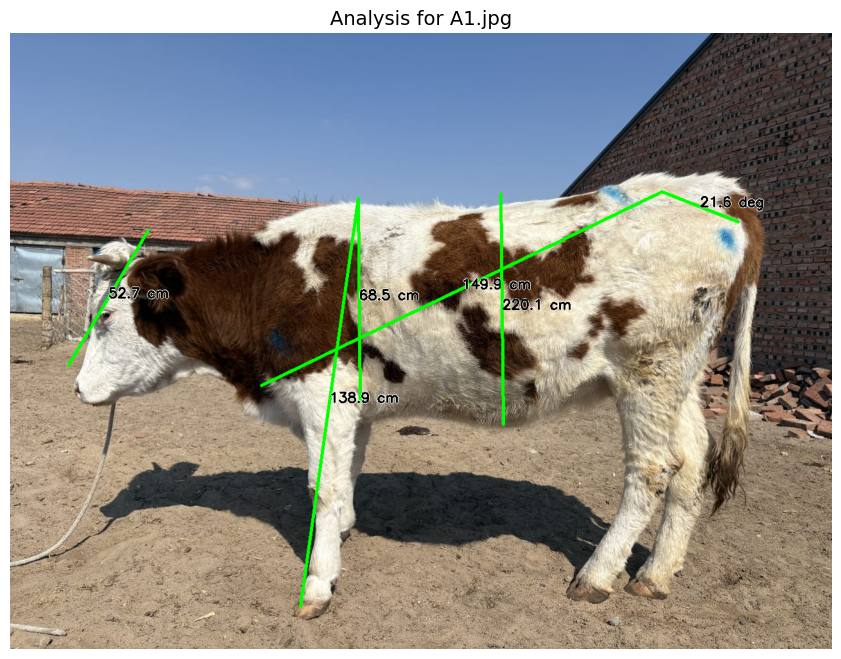

In [ ]:


# =========================================================
# 🖼️ ANALYZE NEW IMAGE (FIXED VERSION)
# =========================================================

# 🔴 PUT THE PATH TO YOUR NEW IMAGE HERE
NEW_IMAGE_PATH = r"C:\Users\veerp\Downloads\Subjects\A1.jpg"

def analyze_new_image(image_path, model, view_type='side'):
    print(f"🚀 Analyzing: {os.path.basename(image_path)}")
    
    # 1. Load Image
    img = cv2.imread(image_path)
    if img is None:
        print(f"❌ Error: Could not find image at {image_path}")
        return
    img_vis = img.copy()
    img_rgb = cv2.cvtColor(img_vis, cv2.COLOR_BGR2RGB) # For plotting
    
    # 2. Run AI Model
    results = model(image_path, verbose=False)
    if not results or not results[0].keypoints:
        print("❌ No animal detected in this image.")
        return

    kpts = results[0].keypoints.data[0].cpu().numpy()
    
    # 3. Calculate Scale (Smart Mode for Side View)
    if view_type == 'side':
        # Anchor: Body Length (Points 2-4) = 150cm
        p2, p4 = kpts[2][:2], kpts[4][:2]
        body_px = np.linalg.norm(p2 - p4)
        scale_factor = body_px / 150.0
        print(f"⚙️  Smart Scale: {scale_factor:.2f} px/cm (Based on Body Length)")
    else:
        # Fallback for Back View
        scale_factor = 4.0 
        print(f"⚙️  Using Default Scale: {scale_factor:.2f} px/cm")

    # 4. Measure & Draw
    config = MEASUREMENT_CONFIG[f'{view_type}_measurements']
    ranges = MEASUREMENT_CONFIG['plausibility_ranges']
    
    print("-" * 60)
    print(f"{'MEASUREMENT':<20} | {'VALUE':<10} | {'STATUS':<10}")
    print("-" * 60)
    
    for name, details in config.items():
        p_idx = details['points']
        if len(p_idx) == 2:
            pt1 = (int(kpts[p_idx[0]][0]), int(kpts[p_idx[0]][1]))
            pt2 = (int(kpts[p_idx[1]][0]), int(kpts[p_idx[1]][1]))
            
            # --- CALCULATE VALUE ---
            if name == 'rump_angle':
                # Angle Logic
                dx, dy = pt2[0] - pt1[0], pt2[1] - pt1[1]
                angle = math.degrees(math.atan2(dy, dx))
                val = abs(angle)
                if val > 90: val = 180 - val # Fix obtuse angles
                unit = "deg"  # <--- CHANGED FROM SYMBOL TO TEXT
            else:
                # Distance Logic
                dist_px = np.linalg.norm(np.array(pt1) - np.array(pt2))
                val = dist_px / scale_factor
                unit = "cm"
                
                # Girth Correction
                if name == 'girth_length':
                    val = val * 3.14159 * 0.90
            
            # --- VALIDATE ---
            min_v, max_v = ranges.get(name, (0, 999))
            is_valid = min_v <= val <= max_v
            
            # --- DRAWING ---
            color = (0, 255, 0) if is_valid else (255, 0, 0) # Green vs Red
            cv2.line(img_rgb, pt1, pt2, color, 4)
            
            # Label
            label = f"{val:.1f} {unit}"
            mid_x, mid_y = (pt1[0]+pt2[0])//2, (pt1[1]+pt2[1])//2
            
            # Draw text with outline
            cv2.putText(img_rgb, label, (mid_x, mid_y), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255,255,255), 4)
            cv2.putText(img_rgb, label, (mid_x, mid_y), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0,0,0), 2)
            
            # Print Text
            status = "✅ PASS" if is_valid else "⚠️ CHECK"
            print(f"{name:<20} | {val:>6.1f} {unit:<3} | {status}")

    # 5. Show Final Image
    print("-" * 60)
    plt.figure(figsize=(12, 8))
    plt.imshow(img_rgb)
    plt.axis('off')
    plt.title(f"Analysis for {os.path.basename(image_path)}", fontsize=14)
    plt.show()

# ======================================
# EXECUTE ON NEW IMAGE
# ======================================
if os.path.exists(NEW_IMAGE_PATH):
    analyze_new_image(NEW_IMAGE_PATH, side_model, 'side')
else:
    print(f"❌ File not found: {NEW_IMAGE_PATH}")
    print("👉 Please edit 'NEW_IMAGE_PATH' at the top of the code!")

🚀 Analyzing Back View: WhatsApp Image 2025-12-08 at 11.02.25 AM.jpeg
⚙️  Smart Scale: 4.03 px/cm (Based on Hip Width)
------------------------------------------------------------
MEASUREMENT          | VALUE      | STATUS    
------------------------------------------------------------
rump_width           |   21.4 cm  | ⚠️ CHECK
hip_width            |   59.8 cm  | ✅ PASS
tail_length          |  100.0 cm  | ⚠️ CHECK
left_hip_height      |  156.4 cm  | ⚠️ CHECK
right_hip_height     |  149.7 cm  | ✅ PASS
------------------------------------------------------------


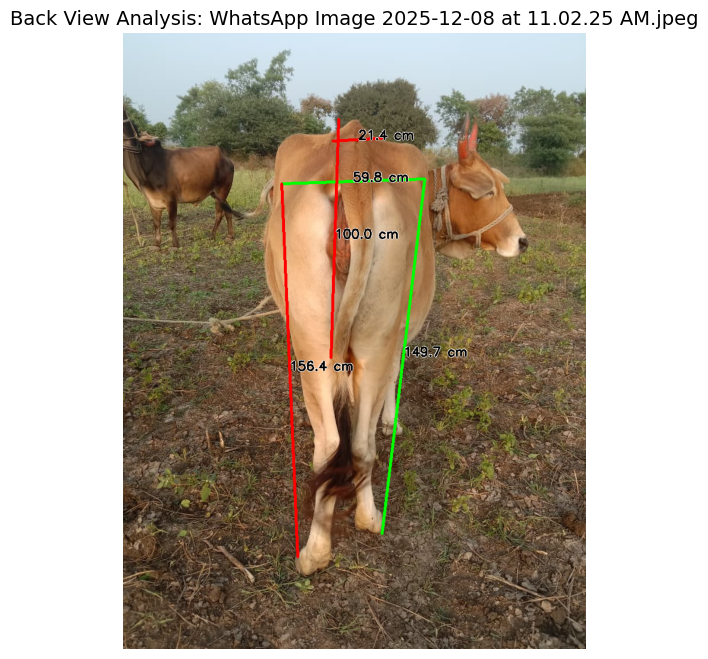

In [ ]:
import math

# =========================================================
# 🖼️ ANALYZE NEW BACK IMAGE
# =========================================================

# 🔴 PUT THE PATH TO YOUR NEW BACK VIEW IMAGE HERE
NEW_BACK_IMAGE_PATH = r"C:\Users\veerp\Downloads\WhatsApp Image 2025-12-08 at 11.02.25 AM.jpeg"

def analyze_back_image(image_path, model):
    print(f"🚀 Analyzing Back View: {os.path.basename(image_path)}")
    
    # 1. Load Image
    img = cv2.imread(image_path)
    if img is None:
        print(f"❌ Error: Could not find image at {image_path}")
        return
    img_vis = img.copy()
    img_rgb = cv2.cvtColor(img_vis, cv2.COLOR_BGR2RGB) # For plotting
    
    # 2. Run AI Model
    results = model(image_path, verbose=False)
    if not results or not results[0].keypoints:
        print("❌ No animal detected in this image.")
        return

    # Get Keypoints (x, y, conf)
    kpts = results[0].keypoints.data[0].cpu().numpy()
    
    # 3. Calculate Scale (Smart Mode for Back View)
    # ---------------------------------------------------------
    # Back View Anchor: Hip Width (Hook-to-Hook)
    # Indices: 2 (Left Hook) and 3 (Right Hook)
    # Reference Value: Approx 60.0 cm for a mature cow
    # ---------------------------------------------------------
    if len(kpts) > 3:
        p_hook_l = kpts[2][:2] # Left Hook
        p_hook_r = kpts[3][:2] # Right Hook
        
        hip_width_px = np.linalg.norm(p_hook_l - p_hook_r)
        
        # Avoid division by zero if points are identical
        if hip_width_px > 10:
            scale_factor = hip_width_px / 60.0  # Reference: 60cm
            print(f"⚙️  Smart Scale: {scale_factor:.2f} px/cm (Based on Hip Width)")
        else:
            scale_factor = 12.0 # Fallback
            print(f"⚠️  Scale Fallback: Points too close. Using default {scale_factor}")
    else:
        scale_factor = 12.0 # Fallback
        print(f"⚠️  Scale Fallback: Keypoints missing. Using default {scale_factor}")

    # 4. Measure & Draw
    # Ensure you have 'back_measurements' in your config
    config = MEASUREMENT_CONFIG.get('back_measurements', {}) 
    ranges = MEASUREMENT_CONFIG.get('plausibility_ranges', {})
    
    print("-" * 60)
    print(f"{'MEASUREMENT':<20} | {'VALUE':<10} | {'STATUS':<10}")
    print("-" * 60)
    
    for name, details in config.items():
        p_idx = details['points']
        
        # Check if indices exist in detection
        if max(p_idx) >= len(kpts):
            continue

        if len(p_idx) == 2:
            pt1 = (int(kpts[p_idx[0]][0]), int(kpts[p_idx[0]][1]))
            pt2 = (int(kpts[p_idx[1]][0]), int(kpts[p_idx[1]][1]))
            
            # --- CALCULATE VALUE ---
            # Distance Logic
            dist_px = np.linalg.norm(np.array(pt1) - np.array(pt2))
            val = dist_px / scale_factor
            unit = "cm"
            
            # --- VALIDATE ---
            min_v, max_v = ranges.get(name, (0, 999))
            is_valid = min_v <= val <= max_v
            
            # --- DRAWING ---
            color = (0, 255, 0) if is_valid else (255, 0, 0) # Green vs Red
            cv2.line(img_rgb, pt1, pt2, color, 4)
            
            # Label
            label = f"{val:.1f} {unit}"
            mid_x, mid_y = (pt1[0]+pt2[0])//2, (pt1[1]+pt2[1])//2
            
            # Draw text with outline
            cv2.putText(img_rgb, label, (mid_x, mid_y), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255,255,255), 4)
            cv2.putText(img_rgb, label, (mid_x, mid_y), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0,0,0), 2)
            
            # Print Text
            status = "✅ PASS" if is_valid else "⚠️ CHECK"
            print(f"{name:<20} | {val:>6.1f} {unit:<3} | {status}")

    # 5. Show Final Image
    print("-" * 60)
    plt.figure(figsize=(12, 8))
    plt.imshow(img_rgb)
    plt.axis('off')
    plt.title(f"Back View Analysis: {os.path.basename(image_path)}", fontsize=14)
    plt.show()

# ======================================
# EXECUTE ON NEW IMAGE
# ======================================
if os.path.exists(NEW_BACK_IMAGE_PATH):
    # Note: Ensure 'back_model' is loaded from Step 2.3
    if 'back_model' in globals():
        analyze_back_image(NEW_BACK_IMAGE_PATH, back_model)
    else:
        print("❌ 'back_model' is not loaded. Please run the model loading step first.")
else:
    print(f"❌ File not found: {NEW_BACK_IMAGE_PATH}")
    print("👉 Please edit 'NEW_BACK_IMAGE_PATH' at the top of the code!")


🚀 Analyzing Back View: A2.jpeg
⚙️  Calibration Source: Rump Width (35.0cm)
    Final Scale Factor: 4.90 px/cm
    ℹ️ Note: Tail-based scale would be 3.79. Diff: 1.11
-----------------------------------------------------------------
MEASUREMENT               | VALUE      | STATUS    
-----------------------------------------------------------------
rump_width                |   35.0 cm | ✅ PASS
hip_width                 |   62.0 cm | ✅ PASS
tail_length               |  100.5 cm | ✅ PASS
left_hip_height           |  133.7 cm | ✅ PASS
right_hip_height          |  141.0 cm | ✅ PASS
thurl_width_l             |   22.0 cm | ✅ PASS
thurl_width_r             |   22.5 cm | ✅ PASS
-----------------------------------------------------------------


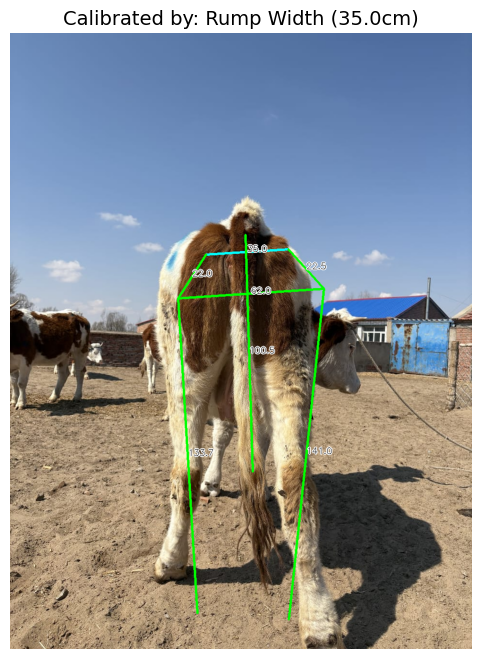

In [ ]:
import numpy as np
import cv2
import os
import matplotlib.pyplot as plt

# =========================================================
# ⚙️ STEP 1: CALIBRATION SETTINGS
# =========================================================
KNOWN_RUMP_WIDTH_CM  = 35.0    # 🟢 FORCE Rump to be 35cm
KNOWN_TAIL_LENGTH_CM = 130.0   # 🟢 Secondary check
KNOWN_HIP_WIDTH_CM   = 60.0    # 🟢 Fallback
TAIL_CORRECTION_FACTOR = 1.0   # 🟢 Adjust if tail is cut off

# =========================================================
# ⚙️ STEP 2: CONFIGURATION
# =========================================================
MEASUREMENT_CONFIG = {
    'back_measurements': {
        'rump_width':        {'points': [0, 1]},   
        'hip_width':         {'points': [2, 3]},   
        'tail_length':       {'points': [4, 5]},   
        'left_hip_height':   {'points': [2, 6]},   
        'right_hip_height':  {'points': [3, 7]},   
        'thurl_width_l':     {'points': [0, 2]},   
        'thurl_width_r':     {'points': [1, 3]},   
    },
    'plausibility_ranges': {
        'rump_width':        (10, 80),  
        'hip_width':         (30, 120),
        'tail_length':       (20, 180), 
        'left_hip_height':   (80, 200),
        'right_hip_height':  (80, 200),
        'thurl_width_l':     (10, 90),
        'thurl_width_r':     (10, 90),
    }
}

# 🔴 PUT YOUR IMAGE PATH HERE
NEW_BACK_IMAGE_PATH = r"C:\Users\veerp\Downloads\Subjects\A2.jpeg"

def analyze_back_image_calibrated(image_path, model):
    print(f"\n🚀 Analyzing Back View: {os.path.basename(image_path)}")
    
    # 1. Load Image
    img = cv2.imread(image_path)
    if img is None: print(f"❌ Error: Not found {image_path}"); return
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    # 2. Run Model
    results = model(image_path, verbose=False)
    if not results or not results[0].keypoints: print("❌ No animal detected."); return
    
    # Get Keypoints
    kpts = results[0].keypoints.data[0].cpu().numpy()

    # 🔧 HELPER: SAFELY GET CONFIDENCE
    # If keypoint is [x, y], return 1.0. If [x, y, conf], return conf.
    def get_conf(pt):
        return pt[2] if len(pt) >= 3 else 1.0

    # 3. CALCULATE SCALE FACTORS
    scales = {}
    
    # A. Rump Scale (Priority)
    if KNOWN_RUMP_WIDTH_CM and get_conf(kpts[0]) > 0.5 and get_conf(kpts[1]) > 0.5:
        px = np.linalg.norm(kpts[0][:2] - kpts[1][:2])
        if px > 10: scales['Rump'] = px / KNOWN_RUMP_WIDTH_CM

    # B. Tail Scale
    if KNOWN_TAIL_LENGTH_CM and get_conf(kpts[4]) > 0.5 and get_conf(kpts[5]) > 0.5:
        px = np.linalg.norm(kpts[4][:2] - kpts[5][:2])
        if px > 10: scales['Tail'] = px / KNOWN_TAIL_LENGTH_CM
            
    # C. Hip Scale (Fallback)
    if KNOWN_HIP_WIDTH_CM and get_conf(kpts[2]) > 0.5 and get_conf(kpts[3]) > 0.5:
        px = np.linalg.norm(kpts[2][:2] - kpts[3][:2])
        if px > 10: scales['Hip'] = px / KNOWN_HIP_WIDTH_CM

    # DECIDE FINAL SCALE
    if 'Rump' in scales:
        final_scale = scales['Rump']
        source = f"Rump Width ({KNOWN_RUMP_WIDTH_CM}cm)"
    elif 'Tail' in scales:
        final_scale = scales['Tail']
        source = f"Tail Length ({KNOWN_TAIL_LENGTH_CM}cm)"
    elif 'Hip' in scales:
        final_scale = scales['Hip']
        source = f"Hip Width ({KNOWN_HIP_WIDTH_CM}cm)"
    else:
        final_scale = 12.0
        source = "Default (12.0)"

    print(f"⚙️  Calibration Source: {source}")
    print(f"    Final Scale Factor: {final_scale:.2f} px/cm")
    
    if 'Rump' in scales and 'Tail' in scales:
        diff = abs(scales['Rump'] - scales['Tail'])
        print(f"    ℹ️ Note: Tail-based scale would be {scales['Tail']:.2f}. Diff: {diff:.2f}")

    # 4. Measure & Draw
    config = MEASUREMENT_CONFIG['back_measurements']
    ranges = MEASUREMENT_CONFIG['plausibility_ranges']
    
    print("-" * 65)
    print(f"{'MEASUREMENT':<25} | {'VALUE':<10} | {'STATUS':<10}")
    print("-" * 65)
    
    for name, details in config.items():
        idx = details['points']
        
        # Check Visibility safely
        if any(get_conf(kpts[i]) < 0.3 for i in idx):
            print(f"{name:<25} | {'---':>6}    | ❌ HIDDEN")
            continue

        pt1 = tuple(kpts[idx[0]][:2].astype(int))
        pt2 = tuple(kpts[idx[1]][:2].astype(int))
        
        # Calculate Distance
        px_dist = np.linalg.norm(np.array(pt1) - np.array(pt2))
        val = px_dist / final_scale
        
        # Apply Corrections
        if name == 'tail_length':
            val = val * TAIL_CORRECTION_FACTOR
        
        # Validate
        min_v, max_v = ranges.get(name, (0, 999))
        is_valid = min_v <= val <= max_v
        
        # Draw
        is_calib = (name == 'rump_width' and 'Rump' in source)
        color = (0, 255, 255) if is_calib else ((0, 255, 0) if is_valid else (255, 0, 0))
        
        cv2.line(img_rgb, pt1, pt2, color, 3)
        
        # Label
        mid = ((pt1[0]+pt2[0])//2, (pt1[1]+pt2[1])//2)
        label = f"{val:.1f}"
        cv2.putText(img_rgb, label, mid, cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255,255,255), 4)
        cv2.putText(img_rgb, label, mid, cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0,0,0), 1)
        
        print(f"{name:<25} | {val:>6.1f} cm | {'✅ PASS' if is_valid else '⚠️ CHECK'}")

    print("-" * 65)
    plt.figure(figsize=(10, 8))
    plt.imshow(img_rgb)
    plt.title(f"Calibrated by: {source}", fontsize=14)  
    plt.axis('off')
    plt.show()

# ======================================
# EXECUTE
# ======================================
if os.path.exists(NEW_BACK_IMAGE_PATH):
    if 'back_model' in globals():
        analyze_back_image_calibrated(NEW_BACK_IMAGE_PATH, back_model)
    else:
        print("❌ 'back_model' not loaded.")
else:
    print(f"❌ File not found: {NEW_BACK_IMAGE_PATH}")

In [ ]:
import pandas as pd
import os
import numpy as np
from scipy.spatial.distance import euclidean

# ==========================================
# STEP 3.9: CALIBRATED RESULTS (ACTUAL VS PREDICTED)
# ==========================================

# ---------------- USER INPUTS ----------------
EXCEL_PATH = r"C:\Users\veerp\Downloads\Subjects\measurements-og.xlsx"       # <--- PASTE EXCEL PATH HERE
IMAGE_DIR  = r"C:\Users\veerp\Downloads\Subjects\side_view"    # <--- PASTE IMAGE FOLDER PATH HERE
# ---------------------------------------------

def print_calibrated_results(excel_path, image_dir, model, limit=22):
    print(f"📂 Loading Data from: {excel_path}")
    print(f"⚠️ Limiting analysis to first {limit} records.")
    
    # 1. Load Excel Data
    try:
        df = pd.read_excel(excel_path)
        df.columns = df.columns.str.lower().str.strip()
        df = df.head(limit)
    except Exception as e:
        print(f"❌ Failed to read Excel: {e}")
        return None

    results = []
    print("\n1️⃣  Scanning images and collecting raw data...")
    
    # 2. Collect Raw Data
    for index, row in df.iterrows():
        img_id = str(row['id']).replace('.jpg', '').replace('.png', '')
        actual_girth = float(row['girth_length'])
        
        # Find image
        img_path = None
        for ext in ['.jpg', '.jpeg', '.png', '.bmp']:
            test_path = os.path.join(image_dir, f"{img_id}{ext}")
            if os.path.exists(test_path):
                img_path = test_path
                break
        
        if img_path:
            try:
                # Predict
                pred = model.predict(img_path, imgsz=640, conf=0.3, verbose=False)[0]
                kpts = pred.keypoints.data[0].cpu().numpy()
                
                # Check Girth Keypoints (5 & 6)
                if kpts[5][2] > 0.4 and kpts[6][2] > 0.4:
                    pixel_dist = euclidean(kpts[5][:2], kpts[6][:2])
                    
                    results.append({
                        'id': img_id,
                        'actual': actual_girth,
                        'pixels': pixel_dist,
                        'ideal_factor': pixel_dist / actual_girth if actual_girth else 0
                    })
            except:
                continue

    if not results:
        print("❌ No valid data found.")
        return None

    # 3. Calculate Calibration Factor
    results_df = pd.DataFrame(results)
    NEW_FACTOR = results_df['ideal_factor'].mean()
    
    # 4. Calculate Final Predictions & Loss
    results_df['predicted'] = results_df['pixels'] / NEW_FACTOR
    results_df['loss'] = results_df['predicted'] - results_df['actual']
    
    # 5. Print Final Table
    print("\n📊 FINAL CALIBRATED RESULTS")
    print("=" * 75)
    print(f"{'Image ID':<15} | {'Actual (cm)':<12} | {'Predicted (cm)':<15} | {'Loss (Diff)':<12}")
    print("-" * 75)
    
    for _, row in results_df.iterrows():
        # Using :+ for loss to show + or - sign
        print(f"{row['id']:<15} | {row['actual']:<12.1f} | {row['predicted']:<15.1f} | {row['loss']:>+9.2f}")
        
    print("-" * 75)
    print(f"🔹 Average Loss (MAE): {results_df['loss'].abs().mean():.2f} cm")
    print(f"🔹 Calibration Factor: {NEW_FACTOR:.4f}")
    
    return NEW_FACTOR

# Run
if 'side_model' in globals():
    CALIBRATED_GIRTH_FACTOR = print_calibrated_results(EXCEL_PATH, IMAGE_DIR, side_model, limit=22)